# 在固定的工作流中使用llm

## 提示词链

- 上一次的输出是下一个的输入
    - 对同一内容进行加工或优化

栗子 (指定主题内容 -> 无要求生成 -> 逻辑条理约束 -> 知识深度 -> 其他 -> 输出)

In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from langchain_ollama import ChatOllama
from langchain.messages import HumanMessage

In [3]:
model_name = "qwen2.5:7b-instruct-q4_K_M"
model = ChatOllama(model=model_name)

In [4]:
class State(TypedDict):
    topic: str
    # T1 outputs
    knowledge: str | None  # T1节点 knowledge_gene -> 判定检测 (业务逻辑判定 - 硬编码 - 常规结构) (llm判定 - 优化器架构 - 新)
    # T2 outputs
    depth_knowledge: str | None # T2节点 knowledge_depth 
    # T3 outputs
    logic_knowledge: str | None # T3节点 knowledge_logic 
    # T4 outputs
    theory_practice_knowledge: str | None # 

In [19]:
def knowledge_gene(state: State) -> dict:
    """
    """
    query_prompt = f"""
    根据主题:
    {state['topic']}
    生成内容。
    """
    result = model.invoke([HumanMessage(content=query_prompt)])
    return {
        "knowledge": result.content
    }

In [17]:
def check(state: State) -> str:
    print(f"{state.get("knowledge", "")}")
    knowledge = state.get("knowledge", "")
    if len(knowledge) > 50:
        return "yes"
    else:
        return "no"

In [20]:
def knowledge_depth(state: State) -> dict:
    knowledge = state.get("knowledge", "")
    depth_prompt = f"""
    以已有的内容:
    {knowledge}为主，
    增添内容的深度。
    """
    result = model.invoke([HumanMessage(content=depth_prompt)])
    return {
        "knowledge_depth": result.content
    }

In [21]:
def logic_knowledge(state: State) -> dict:
    knowledge_depth = state.get("knowledge_depth", "")
    logic_prompt = f"""
    以已有的内容:
    {knowledge_depth}为主，
    使内容更具逻辑性。
    """
    result = model.invoke([HumanMessage(content=logic_prompt)])
    return {
        "logic_knowledge": result.content
    }

In [22]:
def demo_knowledge(state: State) -> dict:
    logic_knowledge = state.get("logic_knowledge", "")
    demo_prompt = f"""
    以已有的内容:
    {logic_knowledge}为主，
    使内容与实际例子相结合，避免空泛。
    """
    result = model.invoke([HumanMessage(content=demo_prompt)])
    return {
        "theory_practice_knowledge": result.content
    }

In [23]:
graph = StateGraph(State)

graph.add_node("knowledge_gene", knowledge_gene)
graph.add_node("knowledge_depth", knowledge_depth)
graph.add_node("logic_knowledge", logic_knowledge)
graph.add_node("demo_knowledge", demo_knowledge)

graph.set_entry_point("knowledge_gene")
graph.add_conditional_edges("knowledge_gene", check, {"yes": "knowledge_depth", "no": "knowledge_gene"})
graph.add_edge("knowledge_depth", "logic_knowledge")
graph.add_edge("logic_knowledge", "demo_knowledge")

app = graph.compile()

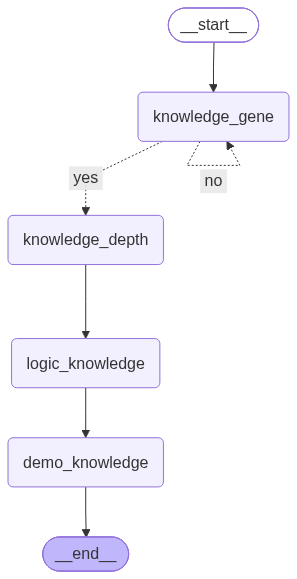

In [25]:
app

In [27]:
config = {
    "configurable": {
        "thread_id": "user1"
    }
}
state = {
    "topic": "咕咕嘎嘎"
}
result = app.invoke(state, config=config)
print("分割线".center(30, "*"))
print(f"{result.get("knowledge", "空大")}")
print(f"{result.get("depth_knowledge", "空大")}")
print(f"{result.get("logic_knowledge", "空大")}")
print(f"{result.get("theory_practice_knowledge", "空大")}")

“咕咕嘎嘎”听起来像是一些拟声词，可能代表了某种声音，或者是某个游戏中角色的叫声。根据这个主题，我会尝试创作一个简单的故事或者描述一个场景。

### 小鸡的日常

在一个宁静的早晨，森林里传来了一阵“咕咕嘎嘎”的声音。这声音是从一片绿油油的草地上发出的。原来，那是一只小鸡在探索它的新家。

“咕咕嘎嘎”是小鸡好奇和兴奋的叫声。在它的叫声中，你可以感受到它对这个世界的好奇和对未来的期待。小鸡在草地上跳跃着，每一步都小心翼翼地，生怕踩到了什么不该踩的东西。

它发现了一个小小的虫子，发出了一串“咕咕嘎嘎”的声音，像是在庆祝自己的发现。然后，它又找到了一颗小石头，同样发出了同样的叫声，似乎是在分享这份新奇。

周围的小动物也被这声音吸引了过来，好奇地围在小鸡身边。一只小兔子轻轻跳跃过来，发出“蹦蹦跳跳”的声音，与小鸡的“咕咕嘎嘎”交织在一起，形成了森林里最美的交响曲。

“咕咕嘎嘎”，不仅是一只小鸡的声音，更是一个充满活力、充满好奇心的小世界。在这样一个充满自然之美的环境中，小鸡学会了更多关于这个世界的新知识，也学会了与朋友们分享快乐。
*************分割线**************
“咕咕嘎嘎”听起来像是一些拟声词，可能代表了某种声音，或者是某个游戏中角色的叫声。根据这个主题，我会尝试创作一个简单的故事或者描述一个场景。

### 小鸡的日常

在一个宁静的早晨，森林里传来了一阵“咕咕嘎嘎”的声音。这声音是从一片绿油油的草地上发出的。原来，那是一只小鸡在探索它的新家。

“咕咕嘎嘎”是小鸡好奇和兴奋的叫声。在它的叫声中，你可以感受到它对这个世界的好奇和对未来的期待。小鸡在草地上跳跃着，每一步都小心翼翼地，生怕踩到了什么不该踩的东西。

它发现了一个小小的虫子，发出了一串“咕咕嘎嘎”的声音，像是在庆祝自己的发现。然后，它又找到了一颗小石头，同样发出了同样的叫声，似乎是在分享这份新奇。

周围的小动物也被这声音吸引了过来，好奇地围在小鸡身边。一只小兔子轻轻跳跃过来，发出“蹦蹦跳跳”的声音，与小鸡的“咕咕嘎嘎”交织在一起，形成了森林里最美的交响曲。

“咕咕嘎嘎”，不仅是一只小鸡的声音，更是一个充满活力、充满好奇心的小世界。在这样一个充满自然之美的环境中，小鸡学会了更多关于这个世界的新知识，也学会了与朋友们分享快乐。
空大
好的，请提供您现有的内容，我会帮助您

## 并行处理

- 固定数据不同角度的内容生成
    - 一个数据分支的不同数据分类，不同分支无关联或关联度小，无法合并处理

In [28]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from langchain_ollama import ChatOllama
from langchain.messages import HumanMessage

In [29]:
model_name = "qwen2.5:7b-instruct-q4_K_M"
model = ChatOllama(model=model_name)

In [31]:
class State(TypedDict):
    topic: str 
    introduction: str
    demo: str
    homework: str
    requirements: str
    results: dict

In [32]:
def introduction_gene(state: State) -> dict:
    introduction_prompt = f"""
    生成一份有关主题为
    {state['topic']}
    的介绍。
    """
    result = model.invoke([HumanMessage(content=introduction_prompt)])
    print(f"[intro] {result.content}")
    return {
        "introduction": result.content
    }

In [33]:
def demo_gene(state: State) -> dict:
    demo_prompt = f"""
    生成一份有关主题为
    {state['topic']}
    的demo演示。
    """
    result = model.invoke([HumanMessage(content=demo_prompt)])
    print(f"[demo] {result.content}")
    return {
        "demo": result.content
    }

In [34]:
def homework_gene(state: State) -> dict:
    homework_prompt = f"""
    生成一份有关主题为
    {state['topic']}
    的作业示例。
    """
    result = model.invoke([HumanMessage(content=homework_prompt)])
    print(f"[homework] {result.content}")
    return {
        "homework": result.content
    }

In [35]:
def requirements_gene(state: State) -> dict:
    requirements_prompt = f"""
    生成一份有关主题为
    {state['topic']}
    的教学要求。不少于3条。
    """
    result = model.invoke([HumanMessage(content=requirements_prompt)])
    print(f"[requirements] {result.content}")
    return {
        "requirements": result.content
    }

In [36]:
def aggregate(state: State) -> dict:
    result = {
        "topic": f"主题 {state['topic']}",
        "introduction": f"介绍 {state['introduction']}",
        "demo": f"例子 {state['demo']}",
        "homework": f"作业示例 {state['homework']}",
        "requirements": f"要求 {state['requirements']}"
    }
    return {
        "results": result
    }

In [37]:
graph = StateGraph(State)

graph.add_node("introduction_gene", introduction_gene)
graph.add_node("demo_gene", demo_gene)
graph.add_node("homework_gene", homework_gene)
graph.add_node("requirements_gene", requirements_gene)
graph.add_node("aggregate", aggregate)

graph.set_entry_point("introduction_gene")
graph.set_entry_point("demo_gene")
graph.set_entry_point("homework_gene")
graph.set_entry_point("requirements_gene")

graph.add_edge("introduction_gene", "aggregate")
graph.add_edge("demo_gene", "aggregate")
graph.add_edge("homework_gene", "aggregate")
graph.add_edge("requirements_gene", "aggregate")

graph.add_edge("aggregate", END)

app = graph.compile()

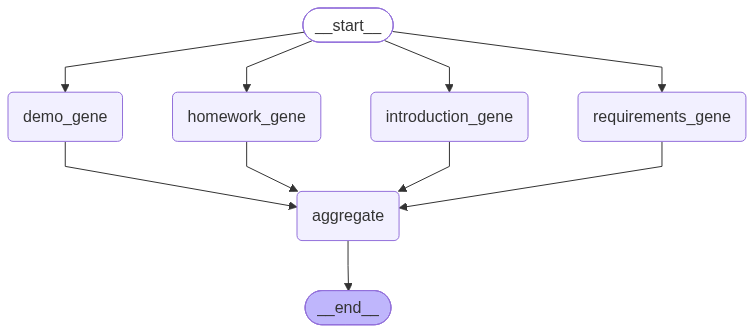

In [38]:
app

In [39]:
config = {
    "configurable": {
        "thread_id": "user1"
    }
}
state = {
    "topic": "数学"
}
result = app.invoke(state, config=config)
print("分割线".center(30, "*"))
print(f"{result.get("results", "空大")}")

[homework] 好的，看起来“咕咕嘎嘎”这个主题需要一些创意来展开。我们可以把它当作一种拟声词或趣味性的表达来处理，比如描述某种声音或创造一个故事。下面我会提供一份作业示例，包括写作和绘画两个部分。

### 作业示例：咕咕嘎嘎

#### 第一部分：写作

请以“咕咕嘎嘎”为主题，创作一篇故事或描述一段场景。你可以把“咕咕嘎嘎”想象成一种独特的声音或动物的叫声。

**示例作品：**

在一个充满魔法与想象的小村庄里，每天清晨都会传来一阵“咕咕嘎嘎”的声音。村里的人们都说，这声音是森林深处的神秘动物发出的，它们在呼唤着森林里的其他生物们醒来。有一天，一个好奇心旺盛的小男孩决定跟随这声音，去寻找它来自的地方。

他穿过茂密的树林，越过清澈的小溪，来到了一片开阔的草地。在那里，他发现了一只穿着绿色小外套的小精灵，正在和一群小动物们玩耍。小精灵告诉他，这“咕咕嘎嘎”的声音是它们快乐生活的体现，是自然与和谐的象征。小男孩听得如痴如醉，决定以后要保护森林，让这种声音永远回荡在大地上。

---

#### 第二部分：绘画

请根据你的故事或场景，画出你心中的“咕咕嘎嘎”世界。可以是插图、场景描绘或者是你想象中动物的画。

**建议：**

- 描述一个充满绿色和生机的森林场景。
- 画面中的角色可以是小男孩、小精灵、动物朋友们等。
- 用色彩和线条来表达“咕咕嘎嘎”的情感和氛围，比如用温暖的色调来表达和谐与快乐。

---

希望这份作业示例能够激发你的创意和想象力！如果你有其他具体要求或需要进一步的帮助，请随时告诉我。
[demo] “咕咕嘎嘎”听起来像是某种拟声词或者特定情境的描述，为了更好地帮助您，我需要进一步明确一下具体需求。是关于某种动物的叫声、某种情境的描述，还是一个创意项目的名称？或者您希望创建一个简单的音频演示？请提供更多的细节，这样我才能更准确地为您生成所需的demo演示。
[intro] 当然，这里有一份有关“咕咕嘎嘎”的创意介绍，这个主题听起来像是一个充满趣味和想象力的概念，我们可以从多个角度进行描述：

### 咕咕嘎嘎：奇妙的声音世界

**定义与来源**

“咕咕嘎嘎”是一个结合了多种动物声音的词汇，它本身可能并没有明确的定义，而是通过不同的语境和创意，赋予了它丰富的意义。这个词汇可能是用来形容一些动物的叫声，或者是创造一种拟声的效果，比如

# 在固定的工作流控制流程

- 根据目的或意图让llm担任分支处理的角色，也就是判断
    - 意图分类
    - 编排分类
    - 评估二分

- 传统流程控制
    - if
    - for
    - while
    - 中断(continue、goto、break)
    - try、assert

## 路由

- 利用llm管理分支
    - 将大任务分成多个子任务，并行

In [11]:
from __future__ import annotations
from typing import Literal
from langchain.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field
from langchain_ollama import ChatOllama

In [5]:
model_name = "qwen2.5:7b-instruct-q4_K_M"
model = ChatOllama(model=model_name)

In [32]:
class intense(BaseModel):
    work_branch: Literal["outline", "intruduction", "homework", "requirement"] = Field(None, description="结构分支可选的执行节点意图集合。是执行的步骤点。outline是大纲，intruduction是介绍，homework是作业，requirement是需求")
    # 意图识别可能有问题。1怎么解决(出现幻觉) -> 换模型。2增强技术 -> RAG、SKILLS、其他数据库。3增强类型描述 -> Field。

In [33]:
structure_model = model.with_structured_output(intense)

In [34]:
from typing_extensions import TypedDict
class State(TypedDict):
    topic: str 
    outputs: str

    decision: str

In [35]:
# 路由节点
def classify_intense(state: State) -> dict:
    decision = structure_model.invoke([
        SystemMessage(content=""),
        HumanMessage(content="")
    ])
    return {
        "decision": decision.work_branch
    }

In [36]:
def router(state: State) -> Literal["outline_gene", "", "", "", END]:
    if state['decision'] == "outline":
        return "outline_gene"
    if state['decision'] == "intruduction":
        return "intruduction_gene"
    if state['decision'] == "homework":
        return "homework_gene"
    if state['decision'] == "requirement":
        return "requirement_gene"
    return END

In [37]:
def outline_gene(state: State) -> dict:
    outline_prompt = f"""
    生成一份有关主题为
    {state['topic']}
    的大纲。
    """
    result = model.invoke([HumanMessage(content=outline_prompt)])
    print(f"[outline] {result.content}")
    return {
        "outputs": result.content
    }

In [38]:
def intruduction_gene(state: State) -> dict:
    intruduction_prompt = f"""
    生成一份有关主题为
    {state['topic']}
    的介绍。
    """
    result = model.invoke([HumanMessage(content=intruduction_prompt)])
    print(f"[intruduction] {result.content}")
    return {
        "outputs": result.content
    }

In [39]:
def homework_gene(state: State) -> dict:
    homework_prompt = f"""
    生成一份有关主题为
    {state['topic']}
    的作业。
    """
    result = model.invoke([HumanMessage(content=homework_prompt)])
    print(f"[homework] {result.content}")
    return {
        "outputs": result.content
    }

In [40]:
def requirement_gene(state: State) -> dict:
    requirement_prompt = f"""
    生成一份有关主题为
    {state['topic']}
    的需求。
    """
    result = model.invoke([HumanMessage(content=requirement_prompt)])
    print(f"[requirement] {result.content}")
    return {
        "outputs": result.content
    }

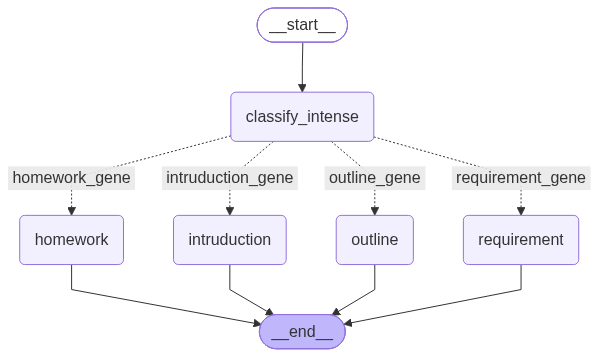

In [41]:
from langgraph.graph import StateGraph, END
graph = StateGraph(State)

graph.add_node("outline", outline_gene)
graph.add_node("intruduction", intruduction_gene)
graph.add_node("homework", homework_gene)
graph.add_node("requirement", requirement_gene)
graph.add_node("classify_intense", classify_intense)

graph.set_entry_point("classify_intense")
graph.add_conditional_edges("classify_intense", router, {"outline_gene": "outline", "intruduction_gene": "intruduction", "homework_gene": "homework", "requirement_gene": "requirement"})
graph.add_edge("outline", END)
graph.add_edge("intruduction", END)
graph.add_edge("homework", END)
graph.add_edge("requirement", END)

app = graph.compile()
app

In [45]:
config = {
    "configurable": {
        "thread_id": "user1"
    }
}
state = {
    "topic": "数学的requirement。"
}
result = app.invoke(state, config=config)
print("分割线".center(30, "*"))
print(f"{result.get("decision", "空大")}")
print(f"{result.get("outputs", "空大")}")

[intruduction] ### 数学课程需求说明书

#### 1. 项目背景
随着科技的发展和信息化时代的到来，数学作为一门基础学科，在多个领域发挥着重要的作用，不仅是科学研究的基础，也是信息技术、工程设计等应用领域的核心支撑。为了适应现代社会的需求，本课程旨在为学生提供全面而深入的数学知识，培养学生的逻辑思维能力和创新意识，为未来的学术研究和职业发展奠定坚实的基础。

#### 2. 课程目标
- **知识目标**：使学生掌握基础数学概念和定理，理解数学在实际问题中的应用；
- **能力目标**：培养学生的抽象思维、逻辑推理和问题解决能力；
- **素质目标**：增强学生的创新意识和实践能力，提高其综合素质。

#### 3. 课程内容
- **基础数学**：包括代数、几何、数论等基本概念和方法；
- **应用数学**：介绍数学在数据分析、计算机科学、金融工程等领域的应用；
- **高级数学**：涵盖微积分、线性代数、概率论等内容，为学生的进一步学习和研究奠定基础；
- **实践项目**：结合实际案例，让学生通过项目实践加深对所学知识的理解和应用。

#### 4. 课程特色
- **理论与实践结合**：通过案例分析和项目实践，使学生能够将理论知识应用于实际问题中；
- **跨学科融合**：邀请不同领域的专家进行讲座，拓展学生的知识面；
- **个性化指导**：提供个性化的学习支持，帮助学生克服学习中的困难。

#### 5. 教学方法
- **讲授法**：由教师进行知识点讲解；
- **讨论法**：组织学生围绕某个主题进行讨论，促进师生互动；
- **案例分析**：通过具体案例分析，提高学生的实际应用能力；
- **项目实践**：通过实际项目，让学生将所学知识应用于实践中。

#### 6. 评估方式
- **平时成绩**：包括出勤、课堂参与度等；
- **作业与小测**：通过作业和小测验检查学生对知识点的掌握情况；
- **项目报告与展示**：通过项目实践，评估学生的综合能力；
- **期末考试**：全面检验学生的学习成果。

#### 7. 课程资源
- **教材**：选用国内外知名出版社的高质量教材；
- **网络资源**：提供丰富的在线学习资源和电子书籍；
- **实验软件**：使用数学建模和分析软件，辅助教学。

#### 8. 结语
本课程旨

## 编排器(意图识别) + llm节点生成内容

In [61]:
from __future__ import annotations
from langgraph.types import Send  # Send的两种用法
from typing import Literal, Annotated
from langchain.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field
from langchain_ollama import ChatOllama
from IPython.display import Image, display
import operator

In [48]:
model_name = "qwen2.5:7b-instruct-q4_K_M"
model = ChatOllama(model=model_name)

### 规划的结构输出定义

- 编排器 就是 任务规划
    - 组织各节点agent做事

In [53]:
class Section(BaseModel):
    name: str = Field(description="本报告节的名称",)
    description: str = Field(description="本部分将涵盖的主要主题和概念的简要概述。",)

class Sections(BaseModel):
    sections: list[Section] = Field(description="报告的节。")

### 流程状态定义

In [50]:
# 父级
class State(TypedDict):
    topic: str  # 报告主题
    sections: list[Section]  # 报告的章节列表
    completed_sections: Annotated[
        list, operator.add
    ]  # 所有工作器并行地向此键写入数据
    final_report: str  # 最终报告

# 子级
class WorkerState(TypedDict):
    section: Section
    complete_section: Annotated[
        list, operator.add
    ]

### 创建工作节点

- 工作流其实就是面向对象的对象 (编译后的状态图 -> 对象[context. checkpointer, store] -> runtime访问)
    - 状态: 成员函数
        - 输入数据
        - 中间临时数据
            - 多个节点共享(至少两个节点间共享)
        - 输出数据
    - 节点: 函数成员
        - 业务逻辑处理数据 -> 中间数据

In [54]:
planner = model.with_structured_output(Sections)
# 编排器
def orchestrator(state: State):
    """为报告生成计划的编排器"""
    # 生成查询
    report_sections = planner.invoke(
        [
            SystemMessage(content="为报告生成一份计划。"),
            HumanMessage(content=f"以下是报告主题：{state['topic']}"),
        ]
    )
    return {"sections": report_sections.sections}

In [55]:
# 工作器
def llm_call(state: WorkerState):
    """工作器撰写报告的一个章节"""
    # 生成章节
    section = model.invoke(
        [
            SystemMessage(
                content="按照提供的名称和描述撰写报告章节。每个章节不加前言。使用Markdown格式。"
            ),
            HumanMessage(
                content=f"以下是章节名称：{state['section'].name}，章节描述：{state['section'].description}"
            ),
        ]
    )
    # 将更新后的章节写入已完成章节列表
    return {"completed_sections": [section.content]}

In [56]:
# 编排任务分发 (不是节点而是边)
# 条件边函数，用于创建多个LLM调用工作器，每个工作器负责撰写报告的一个章节
# 父子图数据在这里整合，同名会根据规则进行修改，不同名需要额外处理
def assign_workers(state: State) -> list[Send]:
    """为计划中的每个章节分配一个工作器"""
    # 通过 Send() API 并行启动章节撰写
    return [Send("llm_call", {"section": s}) for s in state["sections"]]

In [57]:
def synthesizer(state: State):
    """从各章节整合出完整报告"""
    # 已完成章节列表
    completed_sections = state["completed_sections"]
    # 将已完成章节格式化为字符串，以用作后续章节生成的上下文
    completed_report_sections = "\n\n---\n\n".join(completed_sections)
    return {"final_report": completed_report_sections}

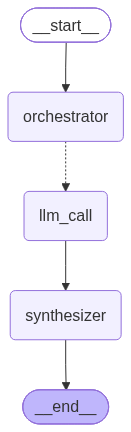

In [62]:
orche_worker_builder = StateGraph(State)

orche_worker_builder.add_node("orchestrator", orchestrator)
orche_worker_builder.add_node("llm_call", llm_call)
orche_worker_builder.add_node("synthesizer", synthesizer)

orche_worker_builder.set_entry_point("orchestrator")
orche_worker_builder.add_conditional_edges("orchestrator", assign_workers, ["llm_call"])
orche_worker_builder.add_edge("llm_call", "synthesizer")
orche_worker_builder.add_edge("synthesizer", END)

app = orche_worker_builder.compile()
app

In [65]:
state = app.invoke({"topic": "撰写一份关于LLM规模定律的报告。"})
from IPython.display import Markdown
Markdown(state["final_report"])

# 报告简介

## 背景

在当前的科技发展浪潮中，大规模语言模型（Large Language Models, LLMs）已经成为自然语言处理领域的一个研究热点。随着技术的进步，LLMs不仅在机器翻译、文本生成、情感分析等任务上取得了显著的成果，而且在一定程度上展示了人类语言处理的潜力。这种技术的进步也引发了对于模型规模与性能之间关系的深入研究。

## 意义

LLMs的规模与性能之间的关系，即规模定律，对于理解模型性能提升的本质具有重要意义。这不仅有助于我们更好地设计和优化大规模语言模型，从而提高其在实际应用中的表现，还能够促进相关技术的发展，推动自然语言处理领域的进步。

## 本报告的目的

本报告旨在对大规模语言模型的规模定律进行系统的梳理与探讨，具体内容包括但不限于以下方面：

- **理论基础**：介绍规模定律的理论背景，包括相关研究理论及模型结构。
- **实证分析**：基于现有数据集和实验结果，分析模型规模与性能之间的关系。
- **实际应用**：讨论规模定律在实际应用中的影响，以及如何根据该定律来选择或设计模型。
- **挑战与展望**：探讨规模定律背后面临的主要挑战，并展望未来的研究方向。

通过本报告，希望读者能够更加深入地理解大规模语言模型规模定律的重要性和应用价值，为相关领域的研究和实践提供参考。

---

## LLM规模定律概述

随着人工智能技术的飞速发展，语言模型（Language Model, LLM）作为其中的重要组成部分，其规模与性能之间的关系成为研究热点。LLM规模定律，即通过增加模型参数数量来提升模型性能的现象，揭示了大规模语言模型在训练和应用中的显著优势。这一现象不仅为模型设计提供了理论依据，也推动了自然语言处理技术的进步。

### 基本概念

LLM规模定律的核心在于模型参数量与模型性能之间的正相关关系。一般来说，模型参数越多，模型在完成任务时的表现越好。这一概念最早由阿里巴巴达摩院的学者提出，并在后续的研究中得到了广泛验证。具体来说，LLM规模定律表明，在足够大的训练数据集和适当训练策略的基础上，增加模型的参数量能够有效提升模型对语言的理解和生成能力。

### 定义

根据达摩院的研究，LLM规模定律可以定义为：“在固定的学习率下，随着模型参数量的增加，训练损失会以指数级下降，同时模型在各种自然语言处理任务上的表现也会显著提升。”这一定义强调了模型参数量与模型性能之间的直接关系，以及训练数据质量和策略对模型效果的影响。

### 在人工智能领域的应用

LLM规模定律在人工智能领域中的应用广泛，特别是在自然语言处理（NLP）任务中表现尤为突出。例如，在机器翻译、文本生成、情感分析等多个任务上，大规模语言模型由于其强大的表征学习能力和泛化能力，能够提供更准确、流畅的结果。此外，这一定律还促进了预训练模型的发展，使得模型在特定任务上的训练成本大幅降低，加速了人工智能技术的商业化进程。

总之，LLM规模定律不仅加深了对语言模型内在机制的理解，也为开发者提供了优化模型设计、提升性能的指导原则。在未来的研究中，探索如何更高效地利用这一定律，同时兼顾模型的可解释性和计算效率，将是重要的研究方向。

---

## LLM规模定律的发现与研究历程

### 1.1 研究背景与重要性

自2020年起，随着语言模型的规模迅速扩张，研究者们在探索其性能与规模之间关系的过程中发现了一种新的规模定律。这一定律不仅揭示了模型规模与性能之间的量化关系，还为模型设计、训练策略优化及资源分配提供了重要的理论依据。因此，对LLM规模定律的研究既具有重要的学术价值，也为实际应用提供了指导意义。

### 1.2 发现过程与关键节点

#### 1.2.1 早期探索

在2020年之前，学术界对于语言模型规模与性能之间关系的探讨尚处于初级阶段。虽然当时已有研究者注意到模型大小对于性能的影响，但缺乏系统性的实验验证与理论解释。这一时期的研究更多依赖于直觉与经验，未形成统一的认知框架。

#### 1.2.2 规模定律初现

2020年，研究团队在大规模预训练模型上进行了一系列实验，发现模型规模的增加显著提升了模型在各种自然语言处理任务上的表现。这表明，随着模型规模的扩大，模型的性能可以呈指数级提升。这一发现首次揭示了规模与性能之间可能存在某种形式的线性关系，为后续研究奠定了基础。

#### 1.2.3 深入研究与验证

随着初步观察结果的公布，越来越多的研究团队开始围绕这一现象展开深入研究。通过更为系统的设计与广泛的实验验证，研究者们逐渐确认了规模与性能之间的定量关系。这一过程中，研究者们通过设计不同规模的模型，对比其在多个任务上的表现，最终得出了规模定律的具体形式。

### 1.3 研究成果与进展

#### 1.3.1 成果概述

经过数年研究，研究团队发现，模型的性能提升与规模之间的关系可由一个简单的数学公式来描述，即：\[P = k \times \sqrt[3]{S}\] 其中，\(P\) 表示模型的性能，\(S\) 表示模型的参数量，\(k\) 为常数。该公式不仅解释了模型规模对性能提升的作用机制，还为预测更大规模模型的性能提供了理论依据。

#### 1.3.2 应用实例

研究者们将规模定律应用于实际应用中，通过增加模型规模来提高模型在各种任务上的表现。例如，在机器翻译任务中，通过将模型规模从10亿参数提升至100亿参数，性能提高了约20%；在文本生成任务中，同样规模的增加也带来了显著的性能改善。此外，规模定律还被用于指导模型的训练与优化，进一步提高了模型的训练效率和性能。

### 1.4 研究思路与方法

#### 1.4.1 实验设计

研究者们通过设计和实施一系列精心策划的实验来验证规模与性能之间的关系。实验包括但不限于：不同规模模型在相同任务上的对比测试、跨任务性能评估、不同训练策略下的模型性能对比等。这些实验设计确保了结果的可靠性和普适性。

#### 1.4.2 数据集选择

为了获得更广泛的应用场景支持，研究团队选择了涵盖不同语言和任务的数据集进行实验。这不仅验证了规模定律的普适性，还为该定律的实际应用提供了更丰富的数据支持。

#### 1.4.3 理论分析

除了实验验证外，研究者们还进行了大量的理论分析，旨在理解规模与性能之间的内在机制。通过对大规模模型结构和训练过程的深入研究，研究者们揭示了模型规模对性能提升的关键影响因素，如参数优化、计算复杂度等。

### 1.5 未来展望

尽管规模定律已经在多个研究中得到验证，但未来的研究仍需进一步探索其边界条件及极限。随着技术的发展，未来可能会出现规模更大的模型，而现有定律是否仍然适用，需要新的实验和理论来验证。此外，如何在保证性能的同时控制模型规模，以及如何平衡性能提升与资源消耗之间的关系，也是一系列值得深入探讨的问题。

---

# LLM规模定律的核心内容

## 模型大小与性能的关系

大规模语言模型（LLMs）的性能与其模型大小密切相关。在研究中发现，随着模型参数数量的增加，模型的能力通常会显著增强。这种关系在一定程度上符合所谓的“规模定律”，表明大型模型能够捕获更复杂的模式和表示，从而在各种任务上实现更好的性能。因此，增加模型的规模被认为是提高模型性能的一种有效策略。尽管这种关系在一定程度上是线性的，但也有研究表明，当模型达到一定大小后，性能的提升会逐渐放缓，呈现出边际效益递减的现象。

## 训练数据量的影响

模型规模的增加也要求相应的训练数据量增长。充足的训练数据对于模型学习复杂表示至关重要。研究发现，较大的模型能够在更大、更多样化的数据集上进行训练，从而捕获更多样化的语言模式和上下文理解能力。此外，数据集的大小直接影响模型在未见过的文本上的泛化能力。大规模模型需要大量的标注数据来进行预训练，以确保其能够对各种语言现象进行有效的建模。因此，数据量的增加有助于提升模型的鲁棒性和泛化性能，使其在面对不同类型的输入时能够表现得更加灵活和可靠。

## 计算资源的需求

随着模型规模的增大，对计算资源的需求也随之增加。训练大规模语言模型需要大量的计算资源，包括高性能的GPU集群、分布式训练环境以及充足的内存支持。大规模模型训练过程中涉及的张量操作和优化算法对计算硬件的要求非常高。此外，大规模模型的推理也对计算资源有较高要求，尤其是在实时应用中，需要确保模型能够快速响应并提供准确的输出。因此，计算资源的充足性是实现大规模语言模型训练和应用的关键因素。为了满足大规模模型的需求，研究和开发团队需要投资于高性能计算设施和优化的硬件架构，以确保模型能够高效地进行训练和推理。

## 总结

综上所述，大规模语言模型（LLMs）的性能、数据需求以及计算资源之间存在着紧密的联系。增加模型规模可以显著提升其性能，但同时也需要相应的大量高质量训练数据和强大的计算资源支持。理解这些关系对于设计和优化LLMs至关重要，有助于研究者和开发人员在追求更强大语言模型的同时，合理规划资源，确保模型能够有效地服务于各种应用场景。

---

## LLM规模定律的应用与影响

随着技术的不断进步，语言模型（LLM）的规模在近年来有了显著的增长，这种现象被称为“规模定律”。规模定律指的是模型参数数量与其性能之间的关系，表明模型参数数量的增加能够带来性能的提升。这种规模效应在自然语言处理（NLP）和机器翻译（MT）等重要领域中有着广泛的应用，并对相关行业产生了深远的影响。

### 1. 自然语言处理中的应用

在自然语言处理领域，规模定律的主要体现是通过增加模型参数来提升语言理解、文本生成等任务的性能。例如，通过增加参数量，模型能够更好地学习语言的复杂结构和语义信息，从而提高在各种NLP任务中的准确率。具体的应用包括但不限于以下方面：

- **文本生成**：通过增强模型的训练数据和参数规模，可以生成更加自然、流畅的文本，包括但不限于自动摘要、对话生成、故事创作等。
- **机器翻译**：更庞大的模型能够捕捉更多的语言对之间的对应关系，从而提高翻译质量。例如，通过大规模的预训练和多语言训练，模型能够处理多种语言对之间的翻译任务。
- **情感分析**：大规模的语言模型可以识别和理解文本中的情感色彩，更好地分析文本的情感倾向，从而在商业决策、舆情监控等领域发挥作用。

### 2. 机器翻译中的应用

在机器翻译领域，规模定律的应用主要体现在通过增加模型的参数数量来提高翻译质量。这种技术进步不仅能够使得翻译更加准确、流畅，还能够实现多语言之间的无缝转换。具体包括以下几个方面：

- **多语言支持**：通过大规模训练，模型能够同时支持多种语言之间的翻译任务，提高了全球化沟通的便利性。
- **翻译质量**：大规模的语言模型能够更好地理解源语言和目标语言之间的细微差异，从而提供更加准确、自然的翻译结果。
- **速度与效率**：大规模模型虽然需要更多的计算资源进行训练，但在实际应用中，经过优化后，其翻译速度和效率依然能够得到显著提升。

### 3. 对相关行业的影响

规模定律在自然语言处理和机器翻译领域的广泛应用，对相关行业产生了重大影响。这些影响包括：

- **技术创新**：规模定律推动了技术的持续创新，使得自然语言处理和机器翻译技术更加成熟和高效。
- **应用扩展**：随着技术的进步，这些技术被广泛应用于各种场景，如电子商务、客户服务、教育等领域，极大地丰富了应用场景。
- **商业价值**：通过提供更高质量、更便捷的服务，相关行业能够吸引更多的用户，提高客户满意度和忠诚度，从而创造更大的商业价值。

总之，规模定律不仅推动了自然语言处理和机器翻译技术的发展，还对相关行业产生了深远的影响，使得技术更加成熟，应用更加广泛，商业价值更加显著。未来，随着技术的进一步发展，规模定律将继续发挥其重要作用，推动自然语言处理和机器翻译技术的不断进步。

---

## LLM规模定律的挑战与未来展望

尽管LLM规模定律为提升模型性能提供了清晰的路径，但在实际部署中，这一路径却充满挑战。计算资源限制、数据隐私问题、模型复杂度的增加以及训练时间的延长等问题，都是阻碍这一路径前行的重要障碍。下面将对这些问题进行详细探讨，并展望未来的研究方向和解决策略。

### 1. 计算资源限制

随着LLM规模的增加，对计算资源的需求也显著增加。超大规模模型需要大量的GPU和高性能的CPU来加速训练和推理过程。此外，这些计算资源的成本也随着规模的增加而成倍增长，这使得大规模模型的研发和部署面临巨大的经济压力。如何在保持模型性能的同时，优化计算资源的使用，是当前研究的一个重要方向。未来的研究可能集中在开发更高效的训练算法、优化模型结构以及探索新的计算架构，以降低对计算资源的依赖。

### 2. 数据隐私问题

随着模型规模的扩大，数据集的容量也随之增加，这带来了数据隐私保护的新挑战。一方面，为了训练更大的模型，需要使用更多的数据集。这些数据集可能包含敏感信息，如何在保证模型性能的前提下，保护这些数据的隐私，是一个亟待解决的问题。另一方面，大规模模型可能更容易受到恶意攻击，如何提升模型的鲁棒性和安全性，也是当前研究的一个重要方向。

### 3. 模型复杂度与训练时间

随着模型规模的增加，模型的复杂度也随之增加，这将导致训练时间的延长。训练时间的延长不仅增加了成本，还可能影响到模型的研发周期。为了解决这一问题，未来的研究可能会集中在开发更高效的训练算法、优化模型结构以及探索新的计算架构。此外，研究者还可能探索如何通过模型蒸馏等技术，将大规模模型的知识转移到更小的模型中，以降低模型复杂度和训练时间。

### 4. 未来研究方向与展望

尽管上述问题给LLM规模定律的应用带来了挑战，但也为未来的研究提供了广阔的前景。未来的研究方向可能包括开发新的训练方法、优化模型结构、提高模型的鲁棒性和安全性，以及探索新的计算架构，以进一步降低计算资源的依赖和提高模型性能。此外，研究者还可能探索如何通过模型蒸馏等技术，将大规模模型的知识转移到更小的模型中，以降低模型复杂度和训练时间。这些研究方向将为LLM规模定律的应用提供更多的可能性。

---

# 报告结论

## 关键点总结
在本报告中，我们深入探讨了语言模型规模定律（LLM规模定律），这一现象不仅揭示了大型语言模型在性能上的显著提升，还为我们理解模型训练与数据处理的关系提供了新的视角。以下是总结的几个关键点：

### 1. 大型语言模型性能的显著提升
LLM规模定律表明，随着模型规模的增长，其在多种任务上的性能显著提高。这种提升不仅体现在语言理解上，还涉及语言生成、代码生成、知识推理等多个领域。这主要是因为大规模模型能够捕捉到更复杂和更丰富的语言模式和结构，从而在处理多样化和复杂问题时展现出更高的准确性与效率。

### 2. 训练与数据处理的关系
研究指出，模型规模的增长在很大程度上依赖于训练数据量的增加。大规模模型的性能提升与其训练数据量成正比，这表明在模型设计中充分利用大量高质量数据是提高其性能的关键因素。因此，未来的研究需更加关注如何高效、系统地收集和利用大规模的高质量数据。

### 3. 计算资源与技术瓶颈
尽管规模定律揭示了大规模语言模型的潜力，但同时也揭示了计算资源和技术上的瓶颈。随着模型规模的不断增加，对硬件的需求也在急剧上升，这使得模型训练成本和时间大幅增加。因此，未来的研究需要探索更高效的算法和更先进的硬件技术，以降低训练成本，提高训练效率。

## 重要性与未来研究建议
LLM规模定律不仅对当前的人工智能领域具有重要意义，也为未来的研究提供了方向和启示。在技术不断进步的背景下，LLM规模定律为我们展示了未来人工智能发展的可能性和挑战。具体而言，该定律强调了在设计和训练大规模模型时应充分考虑计算资源和技术瓶颈。

### 未来研究建议
1. **数据质量与多样性研究**：深入研究如何提高数据的质量和多样性，确保模型在处理复杂任务时更加准确、可靠。
2. **算法与技术优化**：探索更高效的算法和技术，减少训练时间和成本，降低对计算资源的需求。
3. **伦理与应用**：深入探讨大规模语言模型的伦理问题及其在实际应用中的影响，确保技术发展与社会价值的和谐共存。
4. **模型解释性与透明度**：加强模型解释性与透明度的研究，提高模型可解释性，增强用户对模型的信任。
5. **跨领域合作**：促进跨学科合作，将LLM规模定律与其他领域（如心理学、社会学）结合，探讨其在更广泛的应用场景中的潜力。

综上所述，LLM规模定律为未来人工智能研究指明了方向，提供了理论基础，同时也提出了许多亟待解决的问题和挑战。通过进一步的研究与探索，我们有望克服现有障碍，推动人工智能技术的更进一步发展。

## 优化器

In [66]:
from typing import Annotated, List, Literal
import operator
from pydantic import BaseModel, Field
from typing_extensions import TypedDict

In [67]:
model_name = "qwen2.5:7b-instruct-q4_K_M"
model = ChatOllama(model=model_name)

### 评估者的结构化输出定义

In [68]:
class Feedback(BaseModel):
    grade: Literal["好笑", "不好笑"] = Field(
        description="判断这个笑话是否好笑。",
    )
    feedback: str = Field(
        description="如果笑话不好笑，请提供改进建议。",
    )

In [69]:
evaluator = model.with_structured_output(Feedback)

### 工作流状态定义

In [70]:
# 图状态
class State(TypedDict):
    joke: str
    topic: str
    feedback: str
    funny_or_not: str

### 节点

In [78]:
# 节点
def llm_call_generator(state: State):
    """LLM 生成一个笑话"""
    if state.get("feedback"):
        msg = model.invoke(
            f"写一个关于 {state['topic']} 的笑话，但要考虑以下反馈：{state['feedback']}"
        )
    else:
        msg = model.invoke(f"写一个关于 {state['topic']} 的笑话")
    return {"joke": msg.content}

In [72]:
def llm_call_evaluator(state: State):
    grade = evaluator.invoke(f"对笑话{state['joke']}进行评分")
    return {"funny_or_not": grade.grade, "feedback": grade.feedback}

In [73]:
# 条件边函数，根据评估器的反馈决定是路由回笑话生成器还是结束流程。
def route_joke(state: State):
    """根据评估器的反馈，决定是返回笑话生成器还是结束流程"""

    if state["funny_or_not"] == "好笑":
        return "Accepted"
    elif state["funny_or_not"] == "不好笑":
        return "Rejected + Feedback"

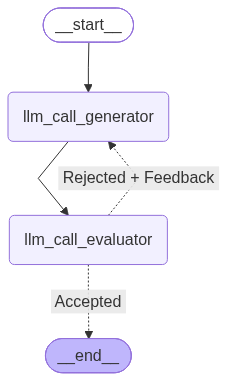

In [80]:
# 构建工作流。
optimizer_builder = StateGraph(State)

# 添加节点。
optimizer_builder.add_node("llm_call_generator", llm_call_generator)
optimizer_builder.add_node("llm_call_evaluator", llm_call_evaluator)

optimizer_builder.set_entry_point("llm_call_generator")
optimizer_builder.add_edge("llm_call_generator", "llm_call_evaluator")
optimizer_builder.add_conditional_edges(
    "llm_call_evaluator",
    route_joke,
    {  # route_joke 返回的名称：下一个要访问的节点名称
        "Accepted": END,
        "Rejected + Feedback": "llm_call_generator",
    },
)

app = optimizer_builder.compile()
app

In [81]:
state = app.invoke({"topic": "驴子"})
print(state["funny_or_not"])
print(state["feedback"])
print(state["joke"])

好笑
这个笑话通过驴子和旅行者的对话，生动地描绘了驴子和旅行者不同的生活方式和乐趣，幽默地展现了驴子对安稳生活的执着。驴子与旅行者交换角色后的真实感受也增加了故事的趣味性。
当然可以，接下来是一个关于驴子的笑话：

有一天，驴子在田里吃草，突然它遇到了一个旅行者。旅行者看着驴子说：“你知道吗？我听说你和牛是好朋友，你俩每天都一起耕地，是不是很有趣？”

驴子看了看旅行者，然后用它那低沉的声音回答：“确实很有趣，不过我更喜欢在田里悠闲地吃草，你呢，旅行者先生？”

旅行者笑了笑说：“我嘛，喜欢旅行。不过，如果你不介意的话，我可以和你交换一段时间，我来耕地，你享受一下旅行的乐趣。”

驴子皱了皱眉，但还是回答：“好吧，就让我们试试。”

结果，驴子耕地时，累得满头大汗；而旅行者在驴子的背上东游西逛，玩得不亦乐乎。驴子最终问道：“旅行者先生，你觉得这交换怎么样？”

旅行者哈哈大笑：“哈哈，你这驴子真是个聪明的家伙，交换当然好，不过我还是喜欢我的脚踏实地。以后还是我们继续交换吧！”

驴子摇摇头，心里想着：看来我还是喜欢安稳地吃草，不换回耕地了。


# ReAct (自主决定下一步的执行流程， 没有所谓的流程编排， 就是单节点循环处理)

- 组合模式:
    - workflow中嵌入局部的agent架构 (以传统业务编排为主)
    - agent的工具嵌入工作流 (以agent架构为主，在工具中加入流程编排)